This notebook serves as a proof of concept for searching spikes in place names to identify events.
The last cell [`places_1577.ipynb`](../notebooks/places_1577.ipynb) uncovers Scotland as occuring significantly in Edward I.

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
import xml.etree.ElementTree as ET
import re

repo_root = Path.cwd().resolve()
if not (repo_root / "1577_files").is_dir():
    repo_root = repo_root.parent

# Locate the (Edward) XML file
edward_path = repo_root / "1577_files" / "regnal_files" / "09_EdwardFirst.xml"

TEI = "{http://www.tei-c.org/ns/1.0}"

root = ET.parse(edward_path).getroot()

# Find Edward I's reign section
edward_entry = root.find(f".//{TEI}div[@type='reign'][@n='Edward I']")

if edward_entry is None:
    raise ValueError("Could not find Edward I's reign section.")

# Extract and normalize the historical text
edward_xml_words = re.sub(r"\s+", " ", " ".join(edward_entry.itertext())).strip()

print(edward_xml_words[:1000])

Edward the fyrſte. 1272. An. reg. 1. EDVVARDE the firſte of that name after the Conqueſt, beganne hys reigne ouer the Realme of of Englande, Vil. Hariſon his chrono gie. the xvj. daye of Nouē ber in the yere of the world, 5239. of our Lorde .1272. of the Saxons .4. after the conqueſt 206. the vacation of the Empire after the deceaſſe of Frederike the the ſeconde as yet enduring (though ſhortly after in the yere next following, Radulf of Habſpurge was elected Emperor) in the third yeare of Philippe the third as then reigning in Fraunce, and Alexander the thirde as yet lyuyng in gouernemente of the Scottiſhe Kyngdome. Thys Edwarde the firſt when his father dyed beyng aboute the age of .xxxv. yeares olde, was as then in the holy lande, or rather in his iourney homewards: but whereſoeuer he was at that preſent, the nobles of the ād after his father was departed this life, . VVeſt. vve Seale de. aſſembled at the new Tēple in London, and cauſing a new ſcale to be made, they ordeyned faith

Found 146 mentions of Scotland/Scotlande.


32    11
23    11
31    10
59    10
28     7
83     6
24     5
66     5
89     5
93     4
Name: count, dtype: int64

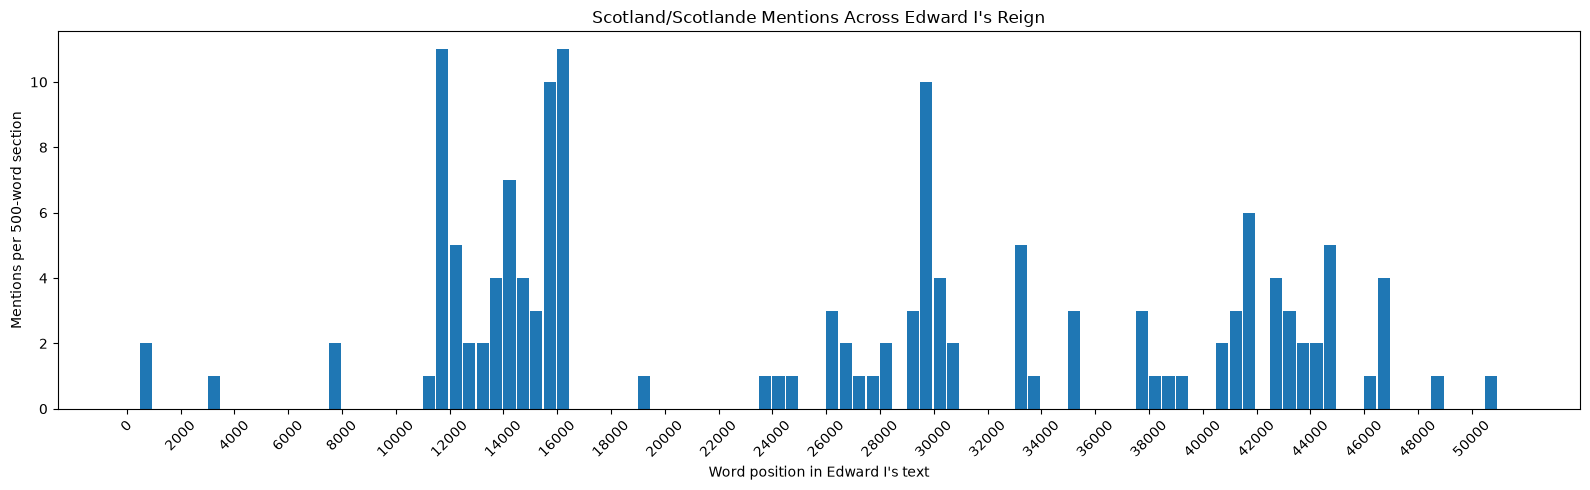

In [31]:
# Split into list of words
edward_words = edward_xml_words.split()

# Find occurrences of "Scotland" and "Scotlande"
scotland_pattern = re.compile(r"(?<!\w)Scotland(?:e)?(?!\w)", re.IGNORECASE)

scotland_positions = [
    match.start() for match in scotland_pattern.finditer(edward_xml_words)
]

# Convert character positions to word positions
word_positions = [len(edward_xml_words[:pos].split()) for pos in scotland_positions]

print(f"Found {len(word_positions)} mentions of Scotland/Scotlande.")

# Count mentions in consecutive 1,000-word sections
window_size = 500
number_of_windows = (len(edward_words) + window_size - 1) // window_size

scotland_counts = (
    pd.Series(word_positions)
    .floordiv(window_size)
    .value_counts()
    .sort_index()
    .reindex(range(number_of_windows), fill_value=0)
)

display(scotland_counts.sort_values(ascending=False).head(10))

# Plot mentions across the text
plt.figure(figsize=(16, 5))

plt.bar(
    scotland_counts.index * window_size,
    scotland_counts.values,
    width=window_size * 0.9,
    align="edge",
)

plt.xlabel("Word position in Edward I's text")
plt.ylabel("Mentions per 500-word section")
plt.title("Scotland/Scotlande Mentions Across Edward I's Reign")
plt.xticks(ticks=range(0, len(edward_words) + 1, 2000), rotation=45)
plt.tight_layout()
plt.show()